# Experiment 9: Music Generation using AI (LSTM and Transformers)

**Aim:** Generate melodies with two sequence models - an LSTM and a Transformer - trained on the soprano lines of
J. S. Bach's chorales, and compare them with objective musical metrics.

In [1]:
import os, time, warnings, collections
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from music21 import corpus, pitch, interval
keras.utils.set_random_seed(9)
rng = np.random.default_rng(9)
STEP = 0.5                       # one time step = an eighth note (0.5 quarter notes)
CTX = 64
print("TensorFlow", tf.__version__, "| time step = eighth note | context =", CTX, "steps")

I0000 00:00:1792698807.283212   12065 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792698808.573612   12065 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | time step = eighth note | context = 64 steps


## 1. Symbolic music dataset
Each chorale is parsed with **music21**, transposed to C major / A minor and its soprano line is converted to a sequence
of tokens, one per eighth-note step: a pitch token at a note onset, `HOLD` while it sustains, and `REST`.

In [2]:
paths = list(corpus.chorales.Iterator(1, 140, returnType="filename"))   # 140 Bach chorales
REST, HOLD, OFFSET = 0, 1, 2
def melody_tokens(path):
    sc = corpus.parse(path)
    k = sc.analyze("key")
    iv = interval.Interval(k.tonic, pitch.Pitch("C" if k.mode == "major" else "A"))
    toks = []
    for n in sc.parts[0].transpose(iv).flatten().notesAndRests:
        steps = max(1, int(round(float(n.quarterLength) / STEP)))
        if n.isRest: toks += [REST] * steps
        else:
            p = n.pitches[-1].midi
            toks += [p + OFFSET] + [HOLD] * (steps - 1)
    return toks
t0 = time.time()
songs = []
for p in paths:
    try: songs.append(melody_tokens(p))
    except Exception: pass
print(f"parsed {len(songs)} chorales in {time.time() - t0:.0f}s | total steps: {sum(map(len, songs)):,}")
pitches = sorted({t - OFFSET for s in songs for t in s if t >= OFFSET})
print("MIDI pitch range:", pitches[0], "-", pitches[-1], "| distinct pitches:", len(pitches))
V = max(max(s) for s in songs) + 1
print("vocabulary size (REST, HOLD + pitches):", V)

NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
def tok_name(t): return "REST" if t == REST else "HOLD" if t == HOLD else NAMES[(t - OFFSET) % 12] + str((t - OFFSET) // 12 - 1)
print("first chorale (first 40 steps):", [tok_name(t) for t in songs[0][:40]])

parsed 140 chorales in 17s | total steps: 15,228
MIDI pitch range: 52 - 88 | distinct pitches: 33
vocabulary size (REST, HOLD + pitches): 91
first chorale (first 40 steps): ['C4', 'HOLD', 'C4', 'HOLD', 'HOLD', 'HOLD', 'G4', 'HOLD', 'E4', 'HOLD', 'HOLD', 'D4', 'C4', 'HOLD', 'C4', 'HOLD', 'HOLD', 'D4', 'E4', 'HOLD', 'D4', 'HOLD', 'HOLD', 'HOLD', 'E4', 'HOLD', 'G4', 'HOLD', 'HOLD', 'HOLD', 'F4', 'HOLD', 'E4', 'HOLD', 'D4', 'HOLD', 'HOLD', 'HOLD', 'C4', 'HOLD']


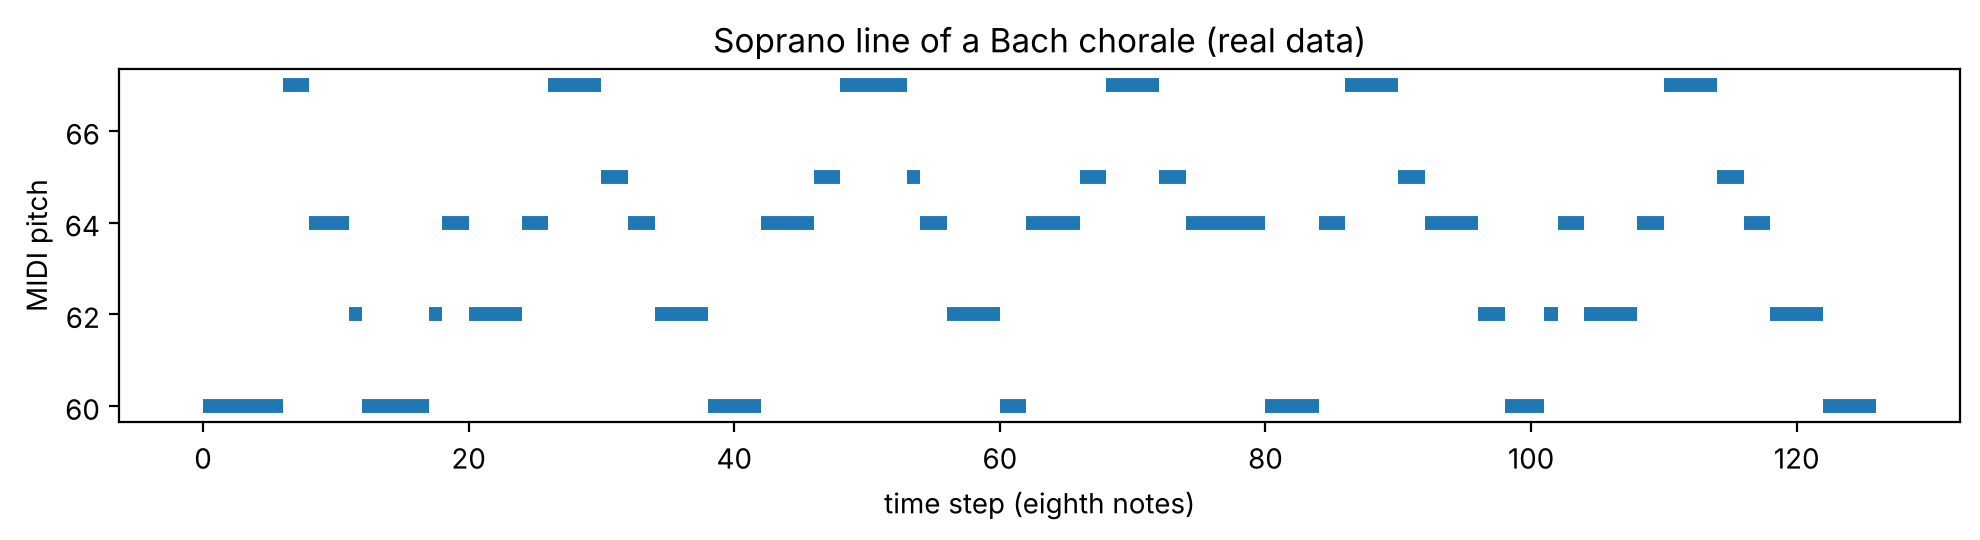

In [3]:
def piano_roll(tokens, ax, title, color="tab:blue"):
    t = 0
    while t < len(tokens):
        if tokens[t] >= OFFSET:
            e = t + 1
            while e < len(tokens) and tokens[e] == HOLD: e += 1
            ax.hlines(tokens[t] - OFFSET, t, e, lw=5, color=color); t = e
        else: t += 1
    ax.set_title(title); ax.set_xlabel("time step (eighth notes)"); ax.set_ylabel("MIDI pitch")
fig, ax = plt.subplots(figsize=(10, 2.8)); piano_roll(songs[0][:160], ax, "Soprano line of a Bach chorale (real data)"); plt.tight_layout(); plt.show()

In [4]:
n_val = 14
def windows(song_list, stride):
    X, Y = [], []
    for s in song_list:
        s = [REST] * 4 + s
        for i in range(0, len(s) - CTX - 1, stride):
            X.append(s[i:i + CTX]); Y.append(s[i + 1:i + CTX + 1])
    return np.array(X, "int32"), np.array(Y, "int32")
Xt, Yt = windows(songs[:-n_val], 2); Xv, Yv = windows(songs[-n_val:], 8)
print("train windows:", Xt.shape, "| validation windows:", Xv.shape)

train windows: (2934, 64) | validation windows: (124, 64)


## 2. Models

In [5]:
def build_lstm():
    return keras.Sequential([layers.Input((None,)), layers.Embedding(V, 48), layers.LSTM(192, return_sequences=True),
                             layers.Dropout(0.2), layers.LSTM(192, return_sequences=True), layers.Dense(V)], name="music_lstm")

class MusicTransformer(keras.Model):
    def __init__(self, d=96, heads=4, nl=3):
        super().__init__()
        self.tok, self.pos = layers.Embedding(V, d), layers.Embedding(CTX, d)
        self.att = [layers.MultiHeadAttention(heads, d // heads) for _ in range(nl)]
        self.ln1 = [layers.LayerNormalization() for _ in range(nl)]; self.ln2 = [layers.LayerNormalization() for _ in range(nl)]
        self.ff = [keras.Sequential([layers.Dense(4 * d, activation="gelu"), layers.Dense(d)]) for _ in range(nl)]
        self.drop = layers.Dropout(0.1); self.lnf = layers.LayerNormalization(); self.head = layers.Dense(V)
    def call(self, x, training=False):
        h = self.drop(self.tok(x) + self.pos(tf.range(tf.shape(x)[1]))[None], training=training)
        for a, l1, l2, f in zip(self.att, self.ln1, self.ln2, self.ff):
            y = l1(h); h = h + self.drop(a(y, y, use_causal_mask=True, training=training), training=training)
            h = h + self.drop(f(l2(h)), training=training)
        return self.head(self.lnf(h))

lstm, trf = build_lstm(), MusicTransformer()
trf(np.zeros((1, CTX), "int32"))
print(f"LSTM        : {lstm.count_params():,} parameters")
print(f"Transformer : {trf.count_params():,} parameters")

LSTM        : 502,699 parameters
Transformer : 359,419 parameters


In [6]:
loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
EPOCHS = 14
hist = {}
for name, m in (("LSTM", lstm), ("Transformer", trf)):
    m.compile(keras.optimizers.Adam(2e-3, clipnorm=1.0), loss, metrics=["sparse_categorical_accuracy"])
    t0 = time.time()
    hist[name] = m.fit(Xt, Yt, validation_data=(Xv, Yv), batch_size=64, epochs=EPOCHS, verbose=0).history
    h = hist[name]
    print(f"{name:12s} {time.time() - t0:4.0f}s | train loss {h['loss'][-1]:.3f} | val loss {h['val_loss'][-1]:.3f} "
          f"| val perplexity {np.exp(h['val_loss'][-1]):.2f} | val next-token accuracy {h['val_sparse_categorical_accuracy'][-1]:.3f}")

LSTM           98s | train loss 0.775 | val loss 1.118 | val perplexity 3.06 | val next-token accuracy 0.646


Transformer   123s | train loss 0.574 | val loss 1.478 | val perplexity 4.38 | val next-token accuracy 0.631


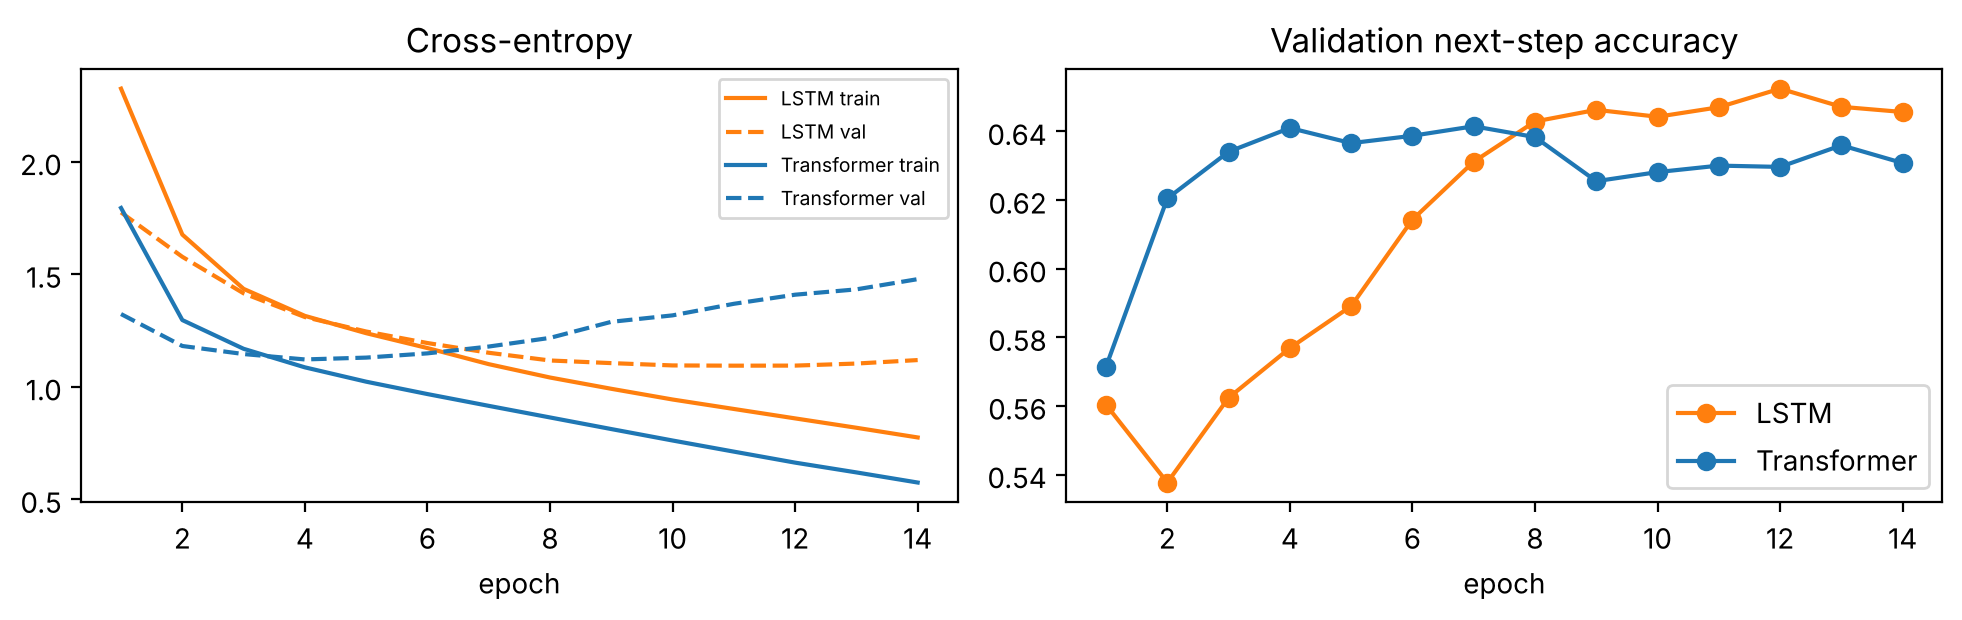

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for name, c in (("LSTM", "tab:orange"), ("Transformer", "tab:blue")):
    e = range(1, EPOCHS + 1)
    ax[0].plot(e, hist[name]["loss"], "-", c=c, label=name + " train"); ax[0].plot(e, hist[name]["val_loss"], "--", c=c, label=name + " val")
    ax[1].plot(e, hist[name]["val_sparse_categorical_accuracy"], "o-", c=c, label=name)
ax[0].set(title="Cross-entropy", xlabel="epoch"); ax[0].legend(fontsize=7)
ax[1].set(title="Validation next-step accuracy", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Generating music

In [8]:
def sample(model, seed, n=256, temperature=0.9, top_k=12):
    seq = list(seed)
    for _ in range(n):
        logits = model(np.array([seq[-CTX:]], "int32"), training=False)[0, -1].numpy() / temperature
        top = np.argsort(logits)[-top_k:]
        p = np.exp(logits[top] - logits[top].max()); p /= p.sum()
        seq.append(int(rng.choice(top, p=p)))
    return seq
seed = [REST] * 4 + songs[-1][:12]               # short seed from a held-out chorale
gen = {"LSTM": sample(lstm, seed), "Transformer": sample(trf, seed)}
for k, v in gen.items(): print(f"{k:12s}:", " ".join(tok_name(t) for t in v[16:60]), "...")

LSTM        : E5 HOLD D5 HOLD C5 HOLD B4 HOLD B4 HOLD HOLD HOLD G#4 HOLD HOLD HOLD REST REST E5 HOLD C5 HOLD D5 HOLD E5 HOLD E5 HOLD D5 HOLD HOLD HOLD E5 HOLD HOLD HOLD D5 HOLD C5 HOLD D5 HOLD C5 B4 ...
Transformer : HOLD F5 E5 HOLD E5 D5 C5 HOLD D5 HOLD HOLD HOLD E5 HOLD E5 HOLD D5 HOLD HOLD HOLD E5 HOLD F5 E5 D5 HOLD E5 HOLD E5 HOLD D5 HOLD E5 HOLD F5 HOLD E5 D5 C5 HOLD C5 HOLD D5 HOLD ...


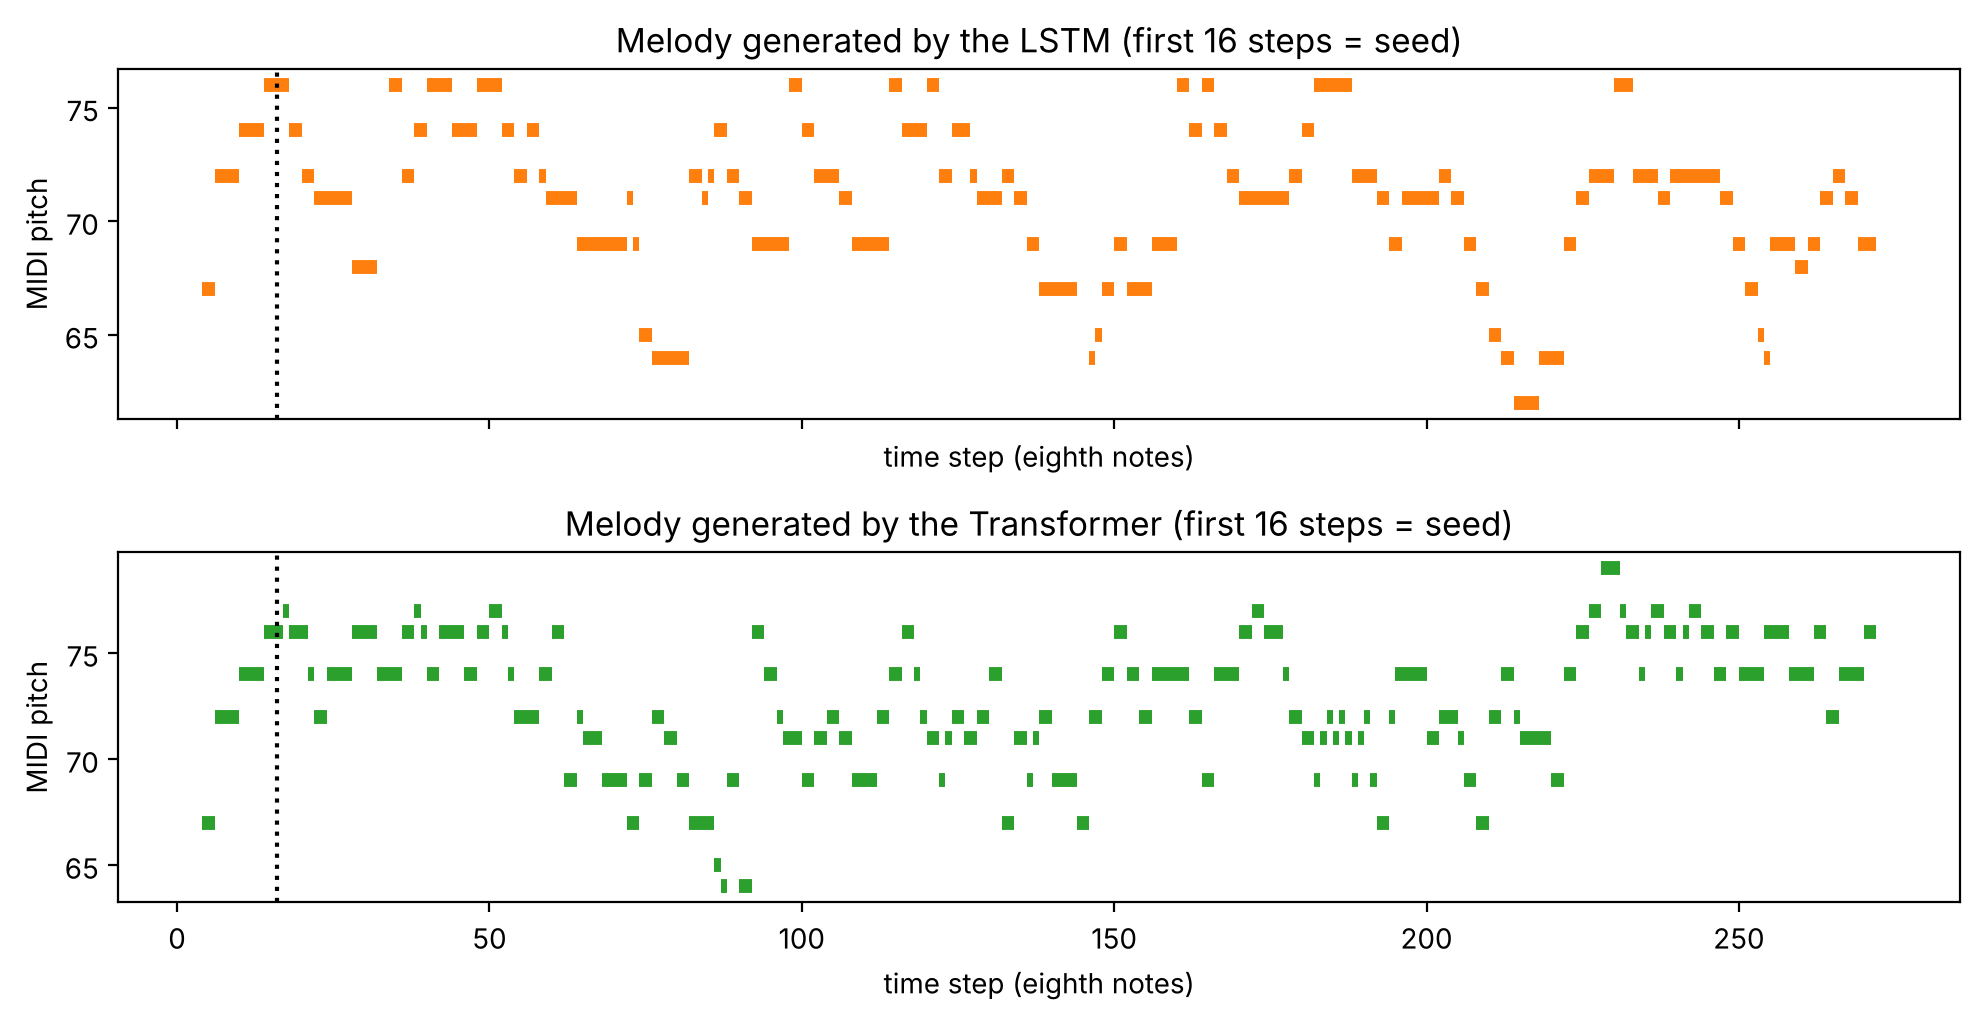

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
for a, (k, c) in zip(axes, (("LSTM", "tab:orange"), ("Transformer", "tab:green"))):
    piano_roll(gen[k], a, f"Melody generated by the {k} (first 16 steps = seed)", c); a.axvline(len(seed), c="k", ls=":")
plt.tight_layout(); plt.show()

## 4. Objective evaluation and audio export

In [10]:
C_MAJOR, A_MINOR = {0, 2, 4, 5, 7, 9, 11}, {9, 11, 0, 2, 4, 5, 8, 7}
def notes(seq): return [t - OFFSET for t in seq if t >= OFFSET]
def onset_notes(seq): return [t - OFFSET for i, t in enumerate(seq) if t >= OFFSET]
def in_key(seq):
    n = notes(seq); return np.mean([(x % 12) in C_MAJOR | A_MINOR for x in n])
def mean_leap(seq):
    n = onset_notes(seq); return np.mean(np.abs(np.diff(n)))
def ngrams(seq, n=6): return {tuple(seq[i:i + n]) for i in range(len(seq) - n + 1)}
train_ng = set().union(*[ngrams(s) for s in songs[:-n_val]])
real = songs[-1] if len(songs[-1]) > 200 else songs[0]
rows = [("Real (held-out)", real)] + [(k, v[len(seed):]) for k, v in gen.items()]
print(f"{'source':16s} {'in-key %':>9s} {'mean leap (semitones)':>22s} {'pitch range':>12s} {'novel 6-grams %':>16s}")
for name, s in rows:
    ng = ngrams(s); novel = np.mean([g not in train_ng for g in ng]) if ng else 0
    n = notes(s)
    print(f"{name:16s} {100 * in_key(s):9.1f} {mean_leap(s):22.2f} {max(n) - min(n):12d} {100 * novel:16.1f}")

source            in-key %  mean leap (semitones)  pitch range  novel 6-grams %
Real (held-out)      100.0                   2.04            7              0.0
LSTM                 100.0                   1.91           14             11.5
Transformer          100.0                   1.95           15             23.5


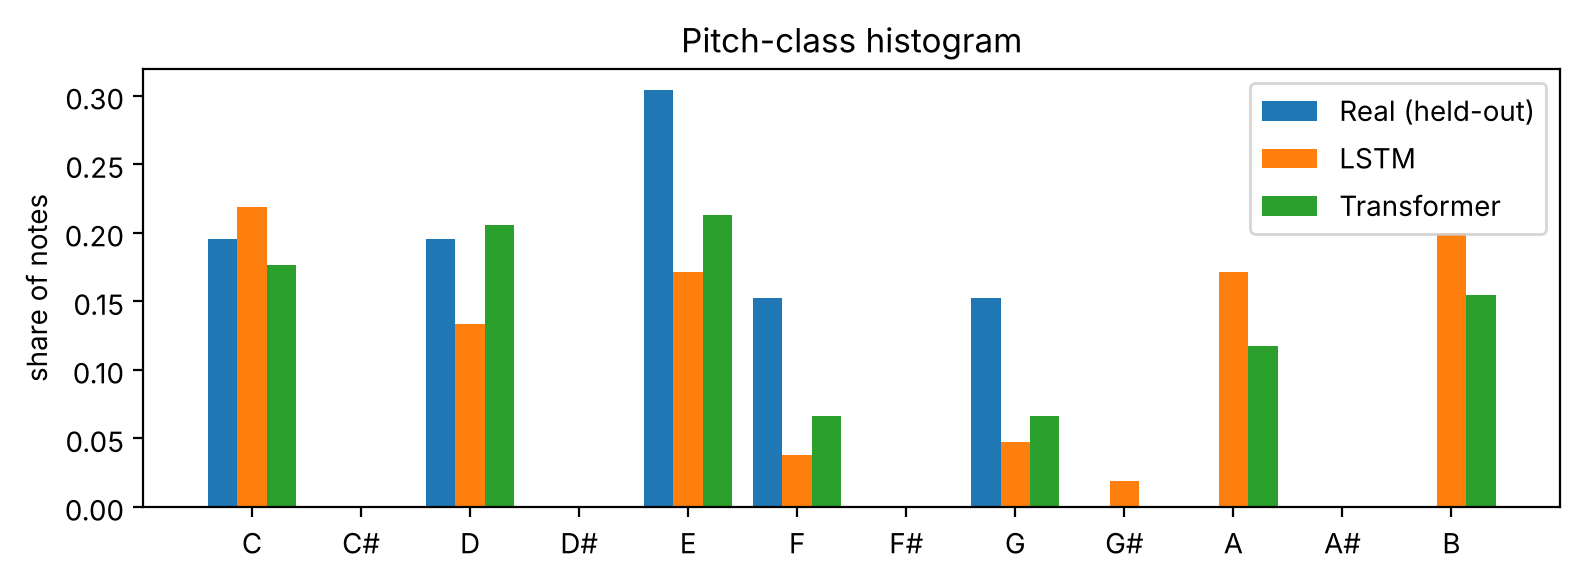

In [11]:
fig, ax = plt.subplots(figsize=(8, 3))
w = 0.27
for i, (name, s) in enumerate(rows):
    h = np.bincount([x % 12 for x in notes(s)], minlength=12); ax.bar(np.arange(12) + (i - 1) * w, h / h.sum(), w, label=name)
ax.set_xticks(range(12)); ax.set_xticklabels(NAMES); ax.set_ylabel("share of notes"); ax.set_title("Pitch-class histogram"); ax.legend()
plt.tight_layout(); plt.show()

In [12]:
import pretty_midi, wave
def to_midi(seq, fname, bpm=100):
    pm = pretty_midi.PrettyMIDI(initial_tempo=bpm); inst = pretty_midi.Instrument(program=73)  # flute
    sec = 60 / bpm * STEP; t = 0
    while t < len(seq):
        if seq[t] >= OFFSET:
            e = t + 1
            while e < len(seq) and seq[e] == HOLD: e += 1
            inst.notes.append(pretty_midi.Note(80, seq[t] - OFFSET, t * sec, e * sec)); t = e
        else: t += 1
    pm.instruments.append(inst); pm.write(fname); return len(inst.notes), len(seq) * sec
def to_wav(seq, fname, bpm=100, sr=16000):
    sec = 60 / bpm * STEP; out = np.zeros(int(len(seq) * sec * sr) + sr); t = 0
    while t < len(seq):
        if seq[t] >= OFFSET:
            e = t + 1
            while e < len(seq) and seq[e] == HOLD: e += 1
            f = 440 * 2 ** ((seq[t] - OFFSET - 69) / 12); tt = np.arange(int((e - t) * sec * sr)) / sr
            env = np.minimum(1, tt / 0.02) * np.exp(-1.5 * tt)
            out[int(t * sec * sr):int(t * sec * sr) + len(tt)] += env * (np.sin(2 * np.pi * f * tt) + 0.4 * np.sin(4 * np.pi * f * tt)); t = e
        else: t += 1
    out = (out / np.abs(out).max() * 0.8 * 32767).astype("<i2")
    with wave.open(fname, "wb") as w: w.setnchannels(1); w.setsampwidth(2); w.setframerate(sr); w.writeframes(out.tobytes())
for k, v in gen.items():
    n_notes, dur = to_midi(v, f"generated_{k.lower()}.mid"); to_wav(v, f"generated_{k.lower()}.wav")
    print(f"generated_{k.lower()}.mid / .wav  -> {n_notes} notes, {dur:.1f} seconds")
from IPython.display import Audio, display
for k in gen: print(k); display(Audio(f"generated_{k.lower()}.wav"))

generated_lstm.mid / .wav  -> 111 notes, 81.6 seconds
generated_transformer.mid / .wav  -> 142 notes, 81.6 seconds
LSTM


Transformer
